# What is the most optimal skill to learn for Data Analysts in Romania?

Methodology:
1. Group skills to determine median salary and likelihood of being in posting
2. Visualize median salary vs percent skill demand
3. Determine if certain technologies are more prevalent

In [1]:
import ast
import pandas as pd
import seaborn as sns
from datasets import load_dataset
import matplotlib.pyplot as plt

# Loading our data
dataset = load_dataset('lukebarousse/data_jobs')
df = dataset['train'].to_pandas()

# Data cleanup
df['job_posted_date'] = pd.to_datetime(df['job_posted_date'])
df['job_skills'] = df['job_skills'].apply(lambda x: ast.literal_eval(x) if pd.notna(x) else x)

c:\Users\dorac\AppData\Local\Programs\Python\Python314\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
df_DA_RO = df[(df['job_title_short']=='Data Analyst') & (df['job_country']=='Romania')].copy()

In [3]:
df_DA_RO = df_DA_RO.dropna(subset=['salary_year_avg'])

df_DA_RO_exploded = df_DA_RO.explode('job_skills')

df_DA_RO_exploded[['salary_year_avg', 'job_skills']].head(5)

,salary_year_avg,job_skills
162997,43200.0,sql
162997,43200.0,python
162997,43200.0,sap
174496,89100.0,spark
174496,89100.0,sap


In [12]:
df_DA_skills = df_DA_RO_exploded.groupby('job_skills')['salary_year_avg'].agg(['count', 'median']).sort_values(by='count', ascending=False)

df_DA_skills = df_DA_skills.rename(columns={'count': 'skill_count', 'median': 'median_salary'})

DA_job_count =len(df_DA_RO)

df_DA_skills['skill_percent'] = df_DA_skills['skill_count'] / DA_job_count * 100

df_DA_skills

,skill_count,median_salary,skill_percent
job_skills,,,
excel,5,56700.0,41.666667
sap,5,89100.0,41.666667
spark,4,89100.0,33.333333
sql,4,71057.0,33.333333
vba,3,56700.0,25.000000
python,2,48107.0,16.666667
go,2,52014.0,16.666667
azure,1,89100.0,8.333333
javascript,1,109120.0,8.333333


In [13]:
skill_percent = 10

df_DA_skills_high_demand = df_DA_skills[df_DA_skills['skill_percent'] >= skill_percent]

df_DA_skills_high_demand

,skill_count,median_salary,skill_percent
job_skills,,,
excel,5,56700.0,41.666667
sap,5,89100.0,41.666667
spark,4,89100.0,33.333333
sql,4,71057.0,33.333333
vba,3,56700.0,25.000000
python,2,48107.0,16.666667
go,2,52014.0,16.666667


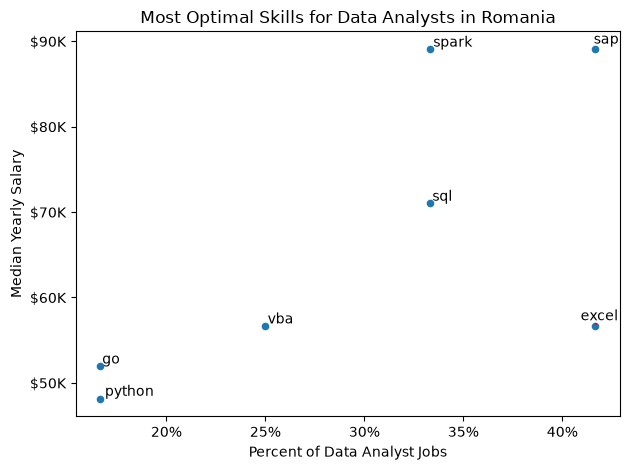

In [17]:
from adjustText import adjust_text

df_DA_skills_high_demand.plot(kind='scatter', x='skill_percent', y='median_salary')

texts = []
for i, txt in enumerate(df_DA_skills_high_demand.index):
    texts.append(plt.text(df_DA_skills_high_demand['skill_percent'].iloc[i], df_DA_skills_high_demand['median_salary'].iloc[i], txt))
    
adjust_text(texts, arrowprops=dict(arrowstyle='->', color='red'))

plt.xlabel('Percent of Data Analyst Jobs')
plt.ylabel('Median Yearly Salary')
plt.title('Most Optimal Skills for Data Analysts in Romania')

from matplotlib.ticker import PercentFormatter

ax = plt.gca()
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, pos: f'${int(y/1000)}K'))
ax.xaxis.set_major_formatter(PercentFormatter(decimals=0))

plt.tight_layout()
plt.show()